# B1 · Data inventory

What race data do we actually have, how often is it sampled, what's missing, and what can serve as labels?

**Sources.** The plan originally said fastf1, but F1's timing archive (which fastf1 reads) now returns
`401 Unauthorized` without a signed-in F1 account. We use the two free APIs instead, downloaded by
`analysis/download.py` into `data/parquet/`:

- **OpenF1**: car data, location, laps, stints, pit stops, race control, weather, positions, intervals,
  session results (2023 onwards).
- **Jolpica** (Ergast successor): race results with a status per driver.

**Split, fixed before any analysis:** tune on **2023–2024**, test once on **2025**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PARQUET = Path('..') / 'data' / 'parquet'
pd.set_option('display.max_columns', 30)

def read(table, seasons=None):
    """Read one table across seasons; adds a `season` column."""
    parts = []
    for d in sorted((PARQUET / table).glob('season=*')):
        season = int(d.name.split('=')[1])
        if seasons and season not in seasons:
            continue
        for f in sorted(d.glob('*.parquet')):
            df = pd.read_parquet(f)
            if len(df):
                parts.append(df.assign(season=season))
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()

sessions = read('sessions')
sessions[['season', 'session_key', 'circuit_short_name', 'country_name', 'date_start']].groupby('season').size()

season
2023    22
2024    24
2025    24
dtype: int64

## 1. Coverage: which tables exist for which races

In [2]:
TABLES = ['laps', 'stints', 'pit', 'race_control', 'weather', 'session_result',
          'position', 'intervals', 'car_data', 'location']

import pyarrow.parquet as pq

def sessions_with_rows(table):
    return {int(f.stem) for f in (PARQUET / table).glob('season=*/*.parquet')
            if pq.ParquetFile(f).metadata.num_rows > 0}

coverage = pd.DataFrame({
    t: sessions.groupby('season')['session_key'].apply(lambda k, t=t: k.isin(sessions_with_rows(t)).sum())
    for t in TABLES
})
coverage.insert(0, 'races', sessions.groupby('season').size())
coverage

,races,laps,stints,pit,race_control,weather,session_result,position,intervals,car_data,location
season,,,,,,,,,,,
2023,22,22,22,16,22,22,22,22,22,0,0
2024,24,24,24,24,24,24,24,24,24,24,24
2025,24,24,24,24,24,24,24,24,24,0,0


## 2. Size: races, drivers, laps and samples

In [3]:
laps = read('laps')
results = read('session_result')
car = read('car_data')
loc = read('location')

size = pd.DataFrame({
    'races': sessions.groupby('season').size(),
    'drivers': results.groupby('season')['driver_number'].nunique(),
    'laps': laps.groupby('season').size(),
    'car_data samples': car.groupby('season').size() if len(car) else 0,
    'location samples': loc.groupby('season').size() if len(loc) else 0,
}).fillna(0).astype(int)
size

/tmp/ipykernel_47039/3622386075.py:20: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()


,races,drivers,laps,car_data samples,location samples
season,,,,,
2023,22,22,24479,0,0
2024,24,25,26629,16550374,16950511
2025,24,21,26265,0,0


## 3. How often is the car sampled?

The CV-style claim "public F1 data is ~4 Hz" has to come from here. We look at the time between consecutive
samples for the same car, only while the race is running (from each car's first lap start to its last lap end).

In [4]:
def race_window(laps):
    w = laps.dropna(subset=['date_start']).copy()
    w['date_end'] = w['date_start'] + pd.to_timedelta(w['lap_duration'].fillna(0), unit='s')
    return w.groupby(['session_key', 'driver_number']).agg(start=('date_start', 'min'), end=('date_end', 'max'))

def in_race(samples, laps):
    w = race_window(laps).reset_index()
    s = samples.merge(w, on=['session_key', 'driver_number'])
    return s[(s['date'] >= s['start']) & (s['date'] <= s['end'])].drop(columns=['start', 'end'])

def intervals_s(samples):
    s = samples.sort_values(['session_key', 'driver_number', 'date'])
    dt = s.groupby(['session_key', 'driver_number'])['date'].diff().dt.total_seconds()
    return dt.dropna()

car_race = in_race(car, laps) if len(car) else car
loc_race = in_race(loc, laps) if len(loc) else loc
dt_car, dt_loc = intervals_s(car_race), intervals_s(loc_race)

summary = pd.DataFrame({
    name: {'samples': len(dt), 'median interval (s)': dt.median(), 'median rate (Hz)': 1 / dt.median(),
           'p95 interval (s)': dt.quantile(.95), 'share of gaps > 1 s': (dt > 1).mean(),
           'longest gap (s)': dt.max()}
    for name, dt in [('car_data', dt_car), ('location', dt_loc)] if len(dt)
}).T
summary

,samples,median interval (s),median rate (Hz),p95 interval (s),share of gaps > 1 s,longest gap (s)
car_data,9361706.0,0.24,4.166667,0.439,0.001249,5.347
location,9564808.0,0.24,4.166667,0.420,0.001224,1.999


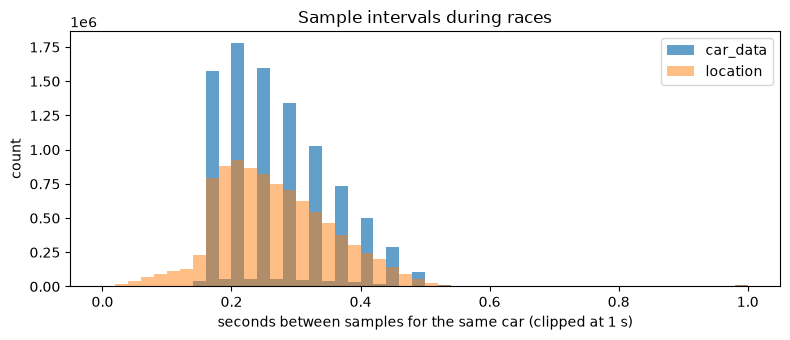

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.arange(0, 1.01, 0.02)
ax.hist(dt_car.clip(upper=1), bins=bins, alpha=.7, label='car_data')
ax.hist(dt_loc.clip(upper=1), bins=bins, alpha=.5, label='location')
ax.set(xlabel='seconds between samples for the same car (clipped at 1 s)', ylabel='count',
       title='Sample intervals during races')
ax.legend(); plt.tight_layout()

## 4. What do the channels look like?

In [6]:
cols = ['speed', 'rpm', 'throttle', 'brake', 'n_gear', 'drs']
car_race[cols].describe(percentiles=[.01, .5, .99]).T

,count,mean,std,min,1%,50%,99%,max
speed,9362171.0,193.219738,79.381532,0.0,0.0,198.0,328.0,369.0
rpm,9362171.0,9748.953052,2111.713306,0.0,0.0,10542.0,11983.0,13496.0
throttle,9362171.0,60.185111,43.158822,0.0,0.0,80.0,100.0,104.0
brake,9362171.0,20.493127,40.373927,0.0,0.0,0.0,100.0,104.0
n_gear,9362171.0,4.966636,2.060666,0.0,0.0,5.0,8.0,128.0
drs,9362171.0,0.703648,2.335358,0.0,0.0,0.0,12.0,15.0


In [7]:
{c: car_race[c].value_counts().sort_index().to_dict() for c in ['brake', 'drs', 'n_gear']}

{'brake': {0: 7444208, 100: 1901999, 104: 15964},
 'drs': {0: 7288272,
  1: 1593577,
  2: 1149,
  3: 432,
  8: 197308,
  9: 960,
  10: 2401,
  12: 256795,
  13: 27,
  14: 21249,
  15: 1},
 'n_gear': {0: 191464,
  1: 120477,
  2: 672897,
  3: 1668712,
  4: 1409710,
  5: 1275113,
  6: 1364587,
  7: 1463297,
  8: 1195545,
  9: 6,
  10: 5,
  11: 8,
  12: 8,
  13: 5,
  14: 5,
  15: 7,
  16: 4,
  17: 11,
  18: 3,
  19: 8,
  20: 6,
  21: 7,
  22: 7,
  23: 5,
  24: 2,
  25: 8,
  26: 5,
  27: 8,
  28: 4,
  29: 8,
  30: 6,
  31: 7,
  32: 8,
  33: 5,
  34: 7,
  35: 5,
  36: 6,
  37: 6,
  38: 6,
  39: 8,
  40: 5,
  41: 7,
  42: 5,
  43: 8,
  44: 4,
  45: 8,
  46: 5,
  47: 6,
  48: 7,
  49: 5,
  50: 5,
  51: 4,
  52: 3,
  53: 1,
  54: 5,
  55: 3,
  56: 2,
  57: 3,
  58: 3,
  59: 3,
  60: 1,
  61: 1,
  62: 3,
  64: 5,
  65: 1,
  66: 2,
  67: 3,
  68: 2,
  70: 4,
  71: 1,
  72: 3,
  73: 2,
  74: 1,
  75: 2,
  78: 2,
  80: 2,
  82: 1,
  83: 1,
  85: 1,
  86: 1,
  88: 2,
  90: 1,
  91: 1,
  92: 1,
  93

**Things to note for B3:** `brake` should be effectively on/off (0 or 100), so `brake === 100` means "pedal
pressed", not "maximum braking". `drs` is a status code, not a position.

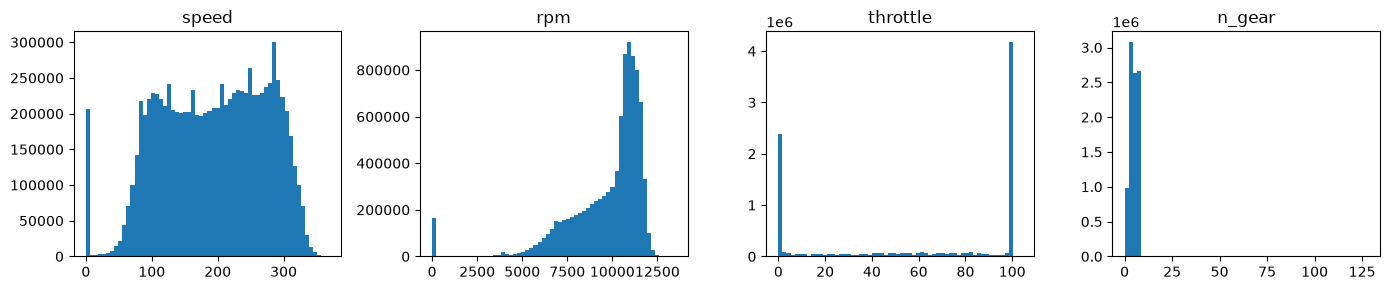

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, c in zip(axes, ['speed', 'rpm', 'throttle', 'n_gear']):
    ax.hist(car_race[c], bins=60); ax.set_title(c)
plt.tight_layout()

## 5. Quick look: three laps at three tracks

/tmp/ipykernel_47039/3185135169.py:3: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  end = lap.date_start + pd.Timedelta(seconds=float(lap.lap_duration))


/tmp/ipykernel_47039/3185135169.py:3: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  end = lap.date_start + pd.Timedelta(seconds=float(lap.lap_duration))
/tmp/ipykernel_47039/3185135169.py:3: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  end = lap.date_start + pd.Timedelta(seconds=float(lap.lap_duration))


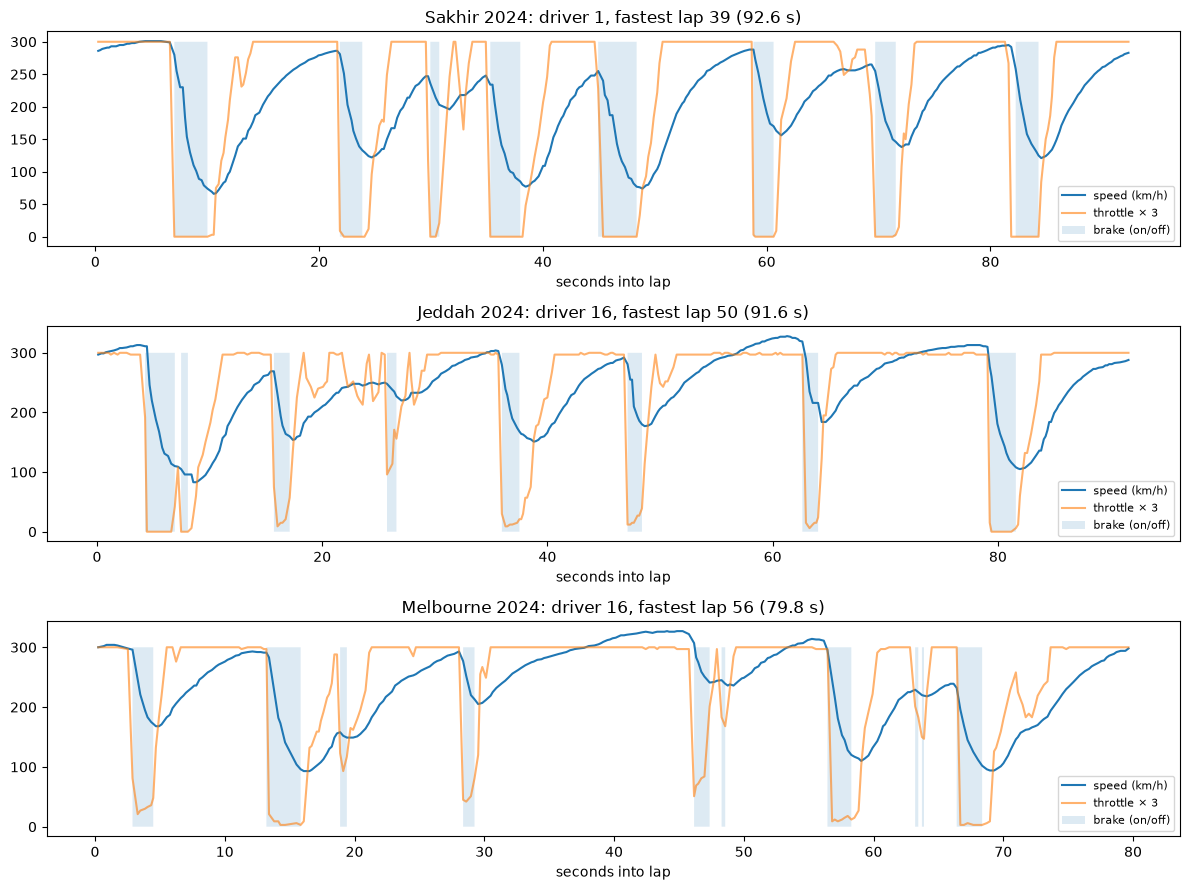

In [9]:
def lap_trace(session_key, driver_number, lap_number):
    lap = laps[(laps.session_key == session_key) & (laps.driver_number == driver_number) & (laps.lap_number == lap_number)].iloc[0]
    end = lap.date_start + pd.Timedelta(seconds=float(lap.lap_duration))
    c = car[(car.session_key == session_key) & (car.driver_number == driver_number)
            & (car.date >= lap.date_start) & (car.date <= end)].copy()
    c['t'] = (c['date'] - lap.date_start).dt.total_seconds()
    return c

with_car = sessions[sessions.session_key.isin(car.session_key.unique())] if len(car) else sessions.iloc[:0]
picks = with_car.drop_duplicates('circuit_short_name').head(3)
fig, axes = plt.subplots(len(picks), 1, figsize=(12, 3 * max(len(picks), 1)), squeeze=False)
for ax, s in zip(axes[:, 0], picks.itertuples()):
    sl = laps[(laps.session_key == s.session_key) & laps.lap_duration.notna() & ~laps.is_pit_out_lap.fillna(False)]
    best = sl.loc[sl.lap_duration.idxmin()]
    for lap_no in [int(best.lap_number)]:
        tr = lap_trace(s.session_key, int(best.driver_number), lap_no)
        ax.plot(tr.t, tr.speed, label='speed (km/h)')
        ax.plot(tr.t, tr.throttle * 3, label='throttle × 3', alpha=.6)
        ax.fill_between(tr.t, 0, tr.brake * 3, alpha=.15, label='brake (on/off)', step='post')
    ax.set_title(f'{s.circuit_short_name} {s.season}: driver {int(best.driver_number)}, fastest lap {lap_no} ({best.lap_duration:.1f} s)')
    ax.set_xlabel('seconds into lap'); ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()

## 6. Laps and stints

In [10]:
lap_quality = laps.groupby('season').agg(
    laps=('lap_number', 'size'),
    missing_duration=('lap_duration', lambda x: x.isna().mean()),
    pit_out_laps=('is_pit_out_lap', lambda x: x.fillna(False).mean()),
)
stints = read('stints')
lap_quality['stints'] = stints.groupby('season').size()
lap_quality['stints missing compound'] = stints.groupby('season')['compound'].apply(lambda x: x.isna().mean())
lap_quality

,laps,missing_duration,pit_out_laps,stints,stints missing compound
season,,,,,
2023,24479,0.004820,0.037256,1350,0.0
2024,26629,0.003230,0.031732,1309,0.0
2025,26265,0.002056,0.031106,1318,0.0


In [11]:
stints.groupby('season')['compound'].value_counts().unstack(fill_value=0)

compound,HARD,INTERMEDIATE,MEDIUM,SOFT,UNKNOWN,WET
season,,,,,,
2023,467,82,488,308,0,5
2024,548,109,489,154,2,7
2025,410,142,549,217,0,0


## 7. What can serve as labels?

B5 needs incidents: cars that retired (ideally with a mechanical cause) and cars stopping on track. Two
sources: Jolpica's per-driver `status`, and OpenF1's session results (`dnf` flag) plus race-control messages.

In [12]:
jolpica = read('jolpica_results')
jolpica.groupby('season')['status'].value_counts().unstack(fill_value=0).T

season,2023,2024,2025
status,,,
Accident,3,0,0
Collision damage,2,0,0
Did not start,3,3,3
Disqualified,2,2,6
Finished,304,287,330
Lapped,70,138,89
Retired,53,49,51
Undertray,1,0,0
Withdrew,2,0,0


In [13]:
dnf = results.groupby('season').agg(entries=('driver_number', 'size'),
                                    dnf=('dnf', lambda x: x.fillna(False).sum()),
                                    dns=('dns', lambda x: x.fillna(False).sum()),
                                    dsq=('dsq', lambda x: x.fillna(False).sum()))
dnf

,entries,dnf,dns,dsq
season,,,,
2023,439,60,3,0
2024,479,49,3,2
2025,479,50,4,6


In [14]:
rc = read('race_control')
rc.groupby('season')['category'].value_counts().unstack(fill_value=0).T

/tmp/ipykernel_47039/3622386075.py:20: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()


season,2023,2024,2025
category,,,
CarEvent,15,5,0
Drs,62,62,67
Flag,813,1148,1080
Other,902,865,961
SafetyCar,48,40,60
SessionStatus,56,54,48


In [15]:
# Race-control messages that name a car, e.g. stopped cars or investigations
named = rc[rc.driver_number.notna()]
print(len(named), 'messages name a car')
named.sample(min(15, len(named)), random_state=0)[['season', 'category', 'flag', 'message']]

1607 messages name a car


,season,category,flag,message
612,2023,Flag,BLUE,WAVED BLUE FLAG FOR CAR 2 (SAR) TIMED AT 16:21:15
1132,2023,Flag,BLUE,WAVED BLUE FLAG FOR CAR 2 (SAR) TIMED AT 15:16:49
6045,2025,Flag,BLUE,WAVED BLUE FLAG FOR CAR 27 (HUL) TIMED AT 15:4...
2803,2024,Flag,BLUE,WAVED BLUE FLAG FOR CAR 14 (ALO) TIMED AT 16:1...
623,2023,Flag,BLUE,WAVED BLUE FLAG FOR CAR 21 (DEV) TIMED AT 16:2...
2824,2024,Flag,BLUE,WAVED BLUE FLAG FOR CAR 23 (ALB) TIMED AT 16:1...
5937,2025,Flag,BLUE,WAVED BLUE FLAG FOR CAR 43 (COL) TIMED AT 16:0...
1958,2024,Flag,BLUE,WAVED BLUE FLAG FOR CAR 77 (BOT) TIMED AT 19:3...
686,2023,Flag,BLUE,WAVED BLUE FLAG FOR CAR 21 (DEV) TIMED AT 15:0...
2754,2024,Flag,BLUE,WAVED BLUE FLAG FOR CAR 2 (SAR) TIMED AT 15:33:27


In [16]:
stopped = rc[rc.message.str.contains('STOPPED|STOPPING|RECOVERY|RETIRED', case=False, na=False)]
print(len(stopped), 'messages mention a stopped/retired car')
stopped[['season', 'lap_number', 'category', 'message']].head(15)

28 messages mention a stopped/retired car


,season,lap_number,category,message
89,2023,8.0,Other,RECOVERY VEHICLE ON TRACK AT TURN 6
136,2023,55.0,Other,RECOVERY VEHICLE ON TRACK AT TURN 3
274,2023,12.0,Other,RECOVERY VEHICLE ON TRACK AT TURN 6
945,2023,35.0,Other,RECOVERY VEHICLE ON TRACK BETWEEN TURN 5 AND T...
1140,2023,17.0,Other,RECOVERY VEHICLE ON TRACK AT TURN 8
1987,2024,7.0,CarEvent,CAR 18 (STR) STOPPED AT TURN 23
1989,2024,8.0,Other,RECOVERY VEHICLE ON TRACK AT TURN 22
2048,2024,17.0,CarEvent,CAR 44 (HAM) STOPPED AT TURN 10
2098,2024,58.0,CarEvent,CAR 63 (RUS) STOPPED AT TURN 6
2132,2024,1.0,Other,CARS 3 (RIC) AND 23 (ALB) STOPPED AT TURN 2


## 8. Findings

**Coverage.** 70 races: 22 in 2023, 24 in 2024, 24 in 2025. Every per-session table exists for every race,
except `pit`, which covers only 16 of the 22 races in 2023. Car data and location are downloaded for 2024 only so far:
16.6M and 17.0M samples, about 160 MB of Parquet. Loading all of it at once peaks at about 6.6 GB of RAM, so B2
onwards should process one session at a time.

**Sample rate.** During races both `car_data` and `location` arrive every **0.24 s (4.17 Hz)**. The 95th
percentile is 0.44 s, 0.12% of gaps are over 1 s, and the longest gap is 5.3 s. So the source is ~4 Hz; anything at
50 Hz in this project is a load-test rate, not the data rate.

**Channel quirks to clean in B2/B3.**
- `brake` is on/off: 0 or 100. There are also 16k samples of 104 (0.17%), which should be treated as 100.
- `throttle` tops out at 104 too; clip to 100.
- `n_gear` is 0–8, plus ~600 junk values from 9 to 128; treat them as missing.
- `drs` is a status code: mostly 0/1 (off), 8 (eligible), 10/12/14 (open). The rare 2, 3, 9, 13 and 15 values
  are unexplained; map open = {10, 12, 14}.
- `speed` is 0–369 km/h and `rpm` 0–13.5k, with no obvious junk.

**Laps and stints.** 77k laps. Only 0.2–0.5% have no duration, and ~3% are pit-out laps (to exclude from
baselines). Every stint has a compound (just 2 "UNKNOWN" in 2024).

**Labels, the main risk for B5.**
- About 50 retirements per season: 53/49/51 "Retired" in Jolpica, and OpenF1's `dnf` flag agrees (60/49/50).
  That is ~150 retirements over three seasons, about 50 of them in the 2025 test season.
- **Cause is almost never given.** 2023 has a handful (Accident 3, Collision damage 2, Undertray 1); 2024 and 2025
  say only "Retired". A mechanical-vs-crash split therefore needs a hand-labelling pass: about 150 rows from race
  reports, with the rule written down first.
- Race control is a weak label source. 1,607 messages name a car, but they are almost all blue flags and
  track limits. Only 28 mention a stopped car or a recovery vehicle, and only 4 name the car ("CAR 44 (HAM) STOPPED
  AT TURN 10"). These are useful for spot-checking incident timing, not as a label set.
- B5 should therefore measure detection on "retired, any cause" first, and on the hand-labelled mechanical subset
  second, with wide confidence intervals given the counts.